# BNPL Credit Risk — EDA of the 13 Selected Features

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/msmkarthik/BNPL-credit/blob/main/BNPL_Selected_Features_EDA.ipynb)

**Context.** A colleague built a BNPL credit risk model ("BNPL Credit Risk Project — Complete Guide") on a different dataset: `bnpl_model_data_clean.csv`. Their final logistic regression uses **13 features**. This notebook is an **exploratory data analysis (EDA) of those 13 features only**: what they look like, how each one relates to default, how they relate to each other, and whether they are stable over time.

**The question the model answers:** what is the chance a customer goes **30 or more days late** on a BNPL payment **in the next 3 months**? The target column is `default_30dpd_next_3m` (1 = yes).

**How this dataset differs from the earlier BNPL dataset:**

| | Earlier dataset | This dataset |
|---|---|---|
| One row is | One customer | **One customer in one month** (7 months per customer) |
| Default rate | 39% | **6.2%** (much rarer, more realistic) |
| Signals | Credit score, income, employment | **BNPL repayment, bank cash flow, UPI behaviour** (Indian new-to-credit lending) |
| Split | We made our own | **Already split by customer** into train / validation / test |

> **How to read this notebook:** before every code cell, a text cell explains **what we are doing and why** and **how the code works**. After important outputs, a **"What we see"** note explains the result in plain English. Section 12 collects all findings. If a basic term is unfamiliar (distribution, median, binning, correlation, IV), see Section 0 of the first EDA notebook, `BNPL_CreditRisk_EDA.ipynb`.

**Running in Google Colab:** put the CSV in a folder called `bnpl` in your Google Drive, then run the cells in order. Section 1.1 connects to your Drive.

## 0. New ideas used in this notebook

**Panel data (customer-months).** Each customer appears in **7 rows**, one per month (months 3 to 9). This is called **panel** or **longitudinal** data. It matters because rows from the same customer are **not independent**: a customer who is struggling in month 5 is probably still struggling in month 6. We must remember this when counting, splitting and evaluating.

**Observation window and performance window.** Every row looks in two directions from its month:
- **Backwards (observation window):** the 13 features summarise the **previous 3 months** of behaviour. This is what the lender knows when deciding.
- **Forwards (performance window):** the target says whether the customer went 30+ days late in the **next 3 months**. This is what we predict.

Because features look backwards and the target looks forwards, there is no overlap in time within a row, so no leakage.

**DPD (days past due).** How many days a payment is late. 0 = paid on time. "30 DPD" = 30 days late, the industry's standard early-default definition.

**Utilisation.** The share of a credit limit that is in use. Using ₹800 of a ₹2,000 limit = 40% utilisation. High utilisation often signals financial stress.

**Account Aggregator (AA) and UPI.** In India, customers can share bank statements (via the RBI-regulated **Account Aggregator** framework) and their **UPI** payment history with a lender, with consent. Most of the 13 features come from these sources.

**Single-feature AUC.** If we ranked customers by **one feature alone** (e.g. lowest bank balance = riskiest), how well would that ranking separate defaulters from good customers? 0.5 = no better than random, 1.0 = perfect. It's a quick way to measure each feature's standalone power. (Section 0.7 of the modelling notebook explains AUC in detail.)

**Information Value (IV).** The credit industry's standard measure of a feature's predictive power (explained in the first EDA notebook, Section 10). Rule of thumb: < 0.02 useless, 0.02–0.1 weak, 0.1–0.3 medium, 0.3–0.5 strong, **> 0.5 "suspiciously strong — check it"**.

**PSI (Population Stability Index).** Measures how much a feature's distribution has **shifted** between two groups (e.g. month 3 vs month 9). Same formula shape as IV. Below 0.1 = stable, 0.1–0.25 = some shift, above 0.25 = major shift.

**Monotonic relationship.** As the feature goes up, default risk moves in **one direction only** (always up, or always down). Credit scorecards prefer monotonic features, because the explanation to a customer must make sense ("more late payments → higher risk", never "a bit higher → lower risk").

## 1. Setup

### 1.1 Connect to the data (Google Colab or your own computer)

#### What we're doing
Telling the notebook where the CSV file is.

- **In Google Colab:** we connect (mount) your Google Drive and read the file from `My Drive/bnpl/`. A pop-up asks for permission; click **Allow**.
- **On your own computer:** we read the file from the notebook's folder.

The colleague's file was downloaded as `bnpl_model_data_clean (1).csv` (browsers add `(1)` when a file name already exists). The code accepts either `bnpl_model_data_clean.csv` or `bnpl_model_data_clean (1).csv`, so you don't need to rename it.

#### How the code works
- `try: from google.colab import drive ... except ImportError:` — the `google.colab` library only exists inside Colab, so this automatically picks the right folder.
- The loop checks each possible file name and keeps the first one that exists. If none is found, it prints what *is* in the folder, to make typos easy to spot.

In [1]:
import os

try:
    # This import only works inside Google Colab
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/bnpl"
    print("Running in Google Colab. Google Drive is connected.")
except ImportError:
    DATA_DIR = "."   # "." means "the folder this notebook is in"
    print("Running locally. Reading the data from the notebook's folder.")

DATA_PATH = None
for name in ["bnpl_model_data_clean.csv", "bnpl_model_data_clean (1).csv"]:
    if os.path.exists(os.path.join(DATA_DIR, name)):
        DATA_PATH = os.path.join(DATA_DIR, name)
        break

if DATA_PATH:
    print("Found the dataset:", DATA_PATH)
else:
    print("Dataset NOT found in", DATA_DIR)
    if os.path.isdir(DATA_DIR):
        print("Files that ARE there:", os.listdir(DATA_DIR))

Running locally. Reading the data from the notebook's folder.
Found the dataset: ./bnpl_model_data_clean.csv


### 1.2 Libraries, chart style and helper functions

#### What we're doing
Loading `pandas`, `numpy`, `matplotlib`, and `roc_auc_score` from scikit-learn (for the single-feature AUC). Then defining small reusable helpers, so later cells stay short:

| Helper | What it does |
|---|---|
| `band(series)` | Groups a feature into bands: one band per value if the feature has 12 or fewer distinct values, otherwise **10 equal-sized bands (deciles)** |
| `default_rate_chart(...)` | Draws the default rate per band as bars, with the overall default rate as a dashed line |
| `information_value(...)` | Computes IV from the bands |
| `psi(...)` | Computes the Population Stability Index between two groups |

#### How the code works
- `pd.qcut(x, 10, duplicates="drop")` splits a numeric column into 10 groups with equal numbers of rows. If many rows share the same value, some edges coincide and are dropped, so a feature can end up with fewer than 10 bands.
- In `default_rate_chart`, `groupby(band)[TARGET].agg(["mean", "size"])` gives the default rate and row count per band (the average of a 0/1 column is the share of 1s).
- `psi` cuts both groups using the **same** 10 band edges (taken from the first group), compares the share of rows in each band, and adds up `(new% − old%) × ln(new% ÷ old%)`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

# ---- Chart style (same as the earlier notebooks) ----
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
GROUP_COLOURS = {"Repayment": BLUE, "Cash flow": ORANGE, "UPI": AQUA}

plt.rcParams.update({
    "figure.figsize": (8, 4), "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False, "font.size": 9, "lines.linewidth": 2,
})

TARGET = "default_30dpd_next_3m"


def band(x, q=10):
    # One band per value for discrete features, otherwise equal-sized deciles
    if x.nunique() <= 12:
        return x
    return pd.qcut(x, q, duplicates="drop")


def band_label(b):
    if isinstance(b, pd.Interval):
        fmt = (lambda v: f"{v:.0f}") if abs(b.right) >= 10 else (lambda v: f"{v:.2f}")
        left = max(b.left, 0) if b.left > -0.01 else b.left   # qcut puts the lowest edge just below the minimum
        return f"{fmt(left)}–{fmt(b.right)}"
    return f"{b:g}"


def default_rate_chart(data, col, ax, overall):
    g = data.groupby(band(data[col]), observed=True)[TARGET].agg(["mean", "size"])
    labels = [band_label(b) for b in g.index]
    bars = ax.bar(labels, g["mean"], color=BLUE, width=0.65)
    ax.axhline(overall, color=ORANGE, linestyle="--", linewidth=1.3)
    for b, v in zip(bars, g["mean"]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.0%}", ha="center", va="bottom", fontsize=7, color=INK)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_ylim(0, max(g["mean"].max() * 1.2, overall * 2))
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    ax.set_title(col)
    return g


def information_value(x, y):
    t = pd.crosstab(band(x), y)
    good, bad = t[0] / t[0].sum(), t[1] / t[1].sum()
    woe = np.log((good + 1e-6) / (bad + 1e-6))
    return ((good - bad) * woe).sum()


def psi(expected, actual, bins=10):
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.clip(np.histogram(expected, edges)[0] / len(expected), 1e-6, None)
    a = np.clip(np.histogram(actual, edges)[0] / len(actual), 1e-6, None)
    return ((a - e) * np.log(a / e)).sum()

print("Ready.")

Ready.


## 2. Load the data and define the 13 features

#### What we're doing
Reading the CSV and writing down the colleague's 13 features in their three groups, together with the **direction they expect** each feature to push risk (from the "13 features in plain words" table in their guide). We'll check these expected directions against the data in Section 8.

| Group | Feature | Plain meaning | Expected: higher value means |
|---|---|---|---|
| Repayment | `ontime_3m` | Share of the last 3 months paid on time (0, ⅓, ⅔ or 1) | Less risk |
| Repayment | `avg_dpd_3m` | Average days past due over the last 3 months | More risk |
| Repayment | `late_cnt` | Number of months ever paid late (since joining) | More risk |
| Repayment | `avg_util_3m` | Share of the BNPL limit in use (3-month average) | More risk |
| Repayment | `since_late` | Months since the last late payment (**12 = never late**) | Less risk |
| Cash flow | `bal_to_income` | Average bank balance ÷ monthly income | Less risk |
| Cash flow | `low_bal_days` | Days per month the bank balance drops very low | More risk |
| Cash flow | `bounced_3m` | Auto-debits that bounced in the last 3 months | More risk |
| Cash flow | `inflow_outflow` | Money in ÷ money out (above 1 = saving) | Less risk |
| Cash flow | `emi_to_income` | Existing loan instalments (EMIs) ÷ income | More risk |
| UPI | `upi_txns` | UPI payments per month | Less risk |
| UPI | `essentials_share` | Share of UPI spend on essentials (groceries, utilities, transport) | Less risk |
| UPI | `bill_reg_3m` | Share of utility bills paid on time (0, ⅓, ⅔ or 1) | Less risk |

Other columns: `user_id`, `month` (3–9), `split` (train / valid / test, assigned by customer), `credit_limit` and `outstanding` (in ₹, used by the colleague only for exposure, not as model inputs), and the target.

#### How the code works
- `FEATURE_GROUPS` is a dictionary: group name → list of features. `FEATURES` flattens it into one list of 13.
- `EXPECTED_DIRECTION` stores +1 ("higher = more risk") or −1 ("higher = less risk") for each feature.

In [3]:
df = pd.read_csv(DATA_PATH)

FEATURE_GROUPS = {
    "Repayment": ["ontime_3m", "avg_dpd_3m", "late_cnt", "avg_util_3m", "since_late"],
    "Cash flow": ["bal_to_income", "low_bal_days", "bounced_3m", "inflow_outflow", "emi_to_income"],
    "UPI":       ["upi_txns", "essentials_share", "bill_reg_3m"],
}
FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]
GROUP_OF = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}

EXPECTED_DIRECTION = {   # +1 = higher value means MORE risk, -1 = LESS risk
    "ontime_3m": -1, "avg_dpd_3m": +1, "late_cnt": +1, "avg_util_3m": +1, "since_late": -1,
    "bal_to_income": -1, "low_bal_days": +1, "bounced_3m": +1, "inflow_outflow": -1, "emi_to_income": +1,
    "upi_txns": -1, "essentials_share": -1, "bill_reg_3m": -1,
}

print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   Features analysed: {len(FEATURES)}")
df.head()

Rows: 21,000   Columns: 19   Features analysed: 13


,user_id,month,split,ontime_3m,avg_dpd_3m,late_cnt,avg_util_3m,since_late,bal_to_income,low_bal_days,bounced_3m,inflow_outflow,emi_to_income,upi_txns,essentials_share,bill_reg_3m,credit_limit,outstanding,default_30dpd_next_3m
0,U1000,3,train,1.000,0.000,0,0.368,12,0.472,3.333,0,1.209,0.084,33.000,0.548,1.000,2000,714.000,0
1,U1001,3,train,1.000,0.000,0,0.765,12,0.478,3.667,2,1.287,0.027,43.667,0.519,1.000,2000,"1,496.000",0
2,U1002,3,train,1.000,0.000,0,0.228,12,0.598,2.667,0,1.210,0.069,47.000,0.569,1.000,2000,534.000,0
3,U1003,3,train,1.000,0.000,0,0.341,12,0.609,0.667,0,1.416,0.089,43.000,0.613,1.000,2000,504.000,0
4,U1004,3,train,1.000,0.000,0,0.236,12,0.520,2.000,0,1.332,0.136,36.333,0.598,1.000,2000,264.000,0


## 3. Data quality

#### What we're doing
The standard checks before trusting any number:
1. **Missing values and duplicate rows.**
2. **One row per customer per month.** In panel data, the same (customer, month) pair must never appear twice.
3. **Ranges** of the 13 features: any impossible values (negative days, shares above 100%)?
4. **Discrete features**: several features only take a few values. We list them to understand their shape.

#### How the code works
- `df.duplicated(["user_id", "month"])` flags any repeated (customer, month) pair.
- `.describe()` gives count, mean, standard deviation, min, quartiles and max; `.T` turns columns into rows.

In [4]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate (customer, month) pairs:", df.duplicated(["user_id", "month"]).sum())
df[FEATURES].describe(percentiles=[0.01, 0.5, 0.99]).T

Missing values: 0
Duplicate rows: 0
Duplicate (customer, month) pairs: 0


,count,mean,std,min,1%,50%,99%,max
ontime_3m,"21,000.000",0.898,0.220,0.000,0.000,1.000,1.000,1.000
avg_dpd_3m,"21,000.000",2.285,7.591,0.000,0.000,0.000,38.667,179.000
late_cnt,"21,000.000",0.597,1.126,0.000,0.000,0.000,5.000,9.000
avg_util_3m,"21,000.000",0.405,0.211,0.020,0.027,0.393,0.899,1.000
since_late,"21,000.000",8.757,4.823,0.000,0.000,12.000,12.000,12.000
bal_to_income,"21,000.000",0.505,0.159,0.000,0.141,0.505,0.870,1.134
low_bal_days,"21,000.000",3.325,2.054,0.000,0.333,3.000,10.333,16.000
bounced_3m,"21,000.000",0.228,0.509,0.000,0.000,0.000,2.000,5.000
inflow_outflow,"21,000.000",1.252,0.098,0.882,1.021,1.254,1.475,1.606
emi_to_income,"21,000.000",0.101,0.066,0.000,0.000,0.100,0.262,0.360


**What we see:**
- **No missing values and no duplicates**, and each (customer, month) pair appears once. The data is clean, which matches the colleague's statement that the features were rebuilt and verified.
- All ranges are plausible: shares are between 0 and 1, counts are non-negative.
- **`avg_dpd_3m` has a long tail:** the median is 0 (most customers pay on time), but the maximum is 179 days. A few severe cases sit far from everyone else.
- `inflow_outflow` is tightly clustered (1st–99th percentile: 1.02–1.48): almost everyone takes in a bit more than they spend.

### 3.1 Discrete features and the special value in `since_late`

#### What we're doing
Six features take only a handful of values. We count each value. We also test something important about `since_late`: the guide says **12 means "never late"**. If that's right, `since_late = 12` should happen for exactly the same rows as `late_cnt = 0`.

A value used as a code for a special situation (like 12 = "never") is called a **sentinel value**. It matters because a model treats 12 as a number: "12 months since the last late payment" sits right next to 8, even though "never late" is a different kind of customer.

#### How the code works
- `value_counts().sort_index()` counts each value, in order.
- `pd.crosstab(a, b)` counts rows for each combination of two conditions; if the sentinel interpretation is right, the off-diagonal cells are 0.

In [5]:
for f in ["ontime_3m", "bill_reg_3m", "late_cnt", "since_late", "bounced_3m"]:
    print(f"{f}: {df[f].value_counts().sort_index().to_dict()}")

print()
print(pd.crosstab(df["since_late"] == 12, df["late_cnt"] == 0,
                  rownames=["since_late == 12"], colnames=["late_cnt == 0"]))

ontime_3m: {0.0: 439, 0.333: 1042, 0.667: 3052, 1.0: 16467}
bill_reg_3m: {0.0: 117, 0.333: 1179, 0.667: 5720, 1.0: 13984}
late_cnt: {0: 14188, 1: 3864, 2: 1489, 3: 748, 4: 376, 5: 165, 6: 105, 7: 43, 8: 16, 9: 6}
since_late: {0: 2162, 1: 1291, 2: 1080, 3: 764, 4: 554, 5: 417, 6: 291, 7: 182, 8: 71, 12: 14188}
bounced_3m: {0: 16937, 1: 3459, 2: 511, 3: 71, 4: 17, 5: 5}

late_cnt == 0     False  True 
since_late == 12              
False              6812      0
True                  0  14188


**What we see:**
- `ontime_3m` and `bill_reg_3m` only take the values 0, ⅓, ⅔ and 1 (0, 1, 2 or 3 of the last 3 months).
- `since_late` runs from 0 to 8, then **jumps straight to 12**. The crosstab confirms that **`since_late = 12` exactly matches `late_cnt = 0`** (14,188 rows, no exceptions), so 12 is a **sentinel meaning "never late"**, not a real count of months.
- About two thirds of rows (14,188 of 21,000) belong to customers who have never been late.
- Large values are rare: `late_cnt` of 7 or more, or `bounced_3m` of 3 or more, appear in under 100 rows each. Default rates for those values will be noisy.

## 4. Panel structure and the train / validation / test split

#### What we're doing
Understanding how rows relate to customers and to time:
1. How many customers, and how many months per customer?
2. How was the data split? The guide says **by customer**: every customer's 7 rows sit in exactly one of train, validation or test. This is essential: if one month of a customer were in training and another in testing, the model would partly be "recognising" a person it has already seen, and the results would look better than reality.
3. Is the default rate similar across splits and across months?

#### How the code works
- `groupby("user_id").size()` counts rows per customer.
- `groupby("user_id")["split"].nunique()` counts how many different splits each customer appears in; it must be 1 for everyone.
- `groupby("split")` / `groupby("month")` then give rows, customers and default rate per group.

In [6]:
rows_per_customer = df.groupby("user_id").size()
print(f"Customers: {df['user_id'].nunique():,}")
print("Rows per customer:", rows_per_customer.value_counts().to_dict())
print("Months:", sorted(df["month"].unique()))
print("Customers appearing in more than one split:", (df.groupby("user_id")["split"].nunique() > 1).sum())

split_summary = df.groupby("split").agg(rows=(TARGET, "size"), customers=("user_id", "nunique"),
                                        defaults=(TARGET, "sum"), default_rate=(TARGET, "mean"))
split_summary.loc[["train", "valid", "test"]].style.format({"rows": "{:,}", "customers": "{:,}",
                                                           "defaults": "{:,}", "default_rate": "{:.1%}"})

Customers: 3,000
Rows per customer: {7: 3000}
Months: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Customers appearing in more than one split: 0


,rows,customers,defaults,default_rate
split,,,,
train,"14,700","2,100",922,6.3%
valid,"3,150",450,196,6.2%
test,"3,150",450,187,5.9%


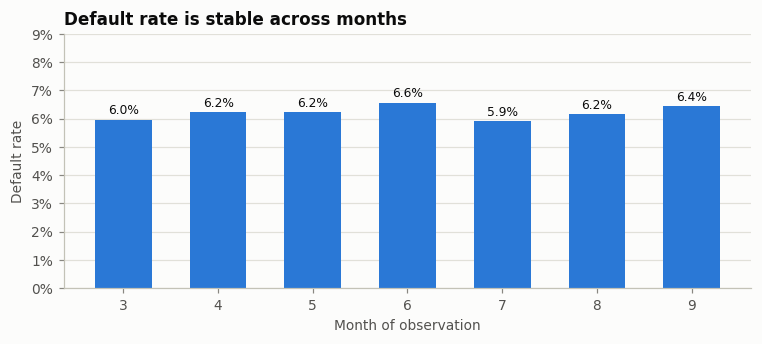

In [7]:
by_month = df.groupby("month")[TARGET].mean()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(by_month.index.astype(str), by_month.values, color=BLUE, width=0.6)
for i, v in enumerate(by_month.values):
    ax.text(i, v + 0.002, f"{v:.1%}", ha="center", fontsize=8, color=INK)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 0.09)
ax.set_xlabel("Month of observation")
ax.set_ylabel("Default rate")
ax.set_title("Default rate is stable across months")
plt.tight_layout()
plt.show()

**What we see:**
- **3,000 customers × 7 months (3 to 9) = 21,000 rows.** Every customer has all 7 months.
- **No customer appears in more than one split**, confirming the colleague split by customer: 2,100 customers in train, 450 in validation, 450 in test.
- The default rate is similar in every split (train 6.3%, validation 6.2%, test 5.9%) and every month (5.9%–6.6%). There's no trend over time in the outcome itself.

## 5. The target: how rare is default, and how "sticky" is it?

#### What we're doing
1. **Overall default rate**, counted in rows (customer-months) and in customers.
2. **Persistence:** if a customer-month is flagged as default, how likely is the *same customer's next month* to be flagged too?

Why persistence matters: the target for month 5 covers months 6–8; for month 6 it covers months 7–9. The two windows **overlap by two months**, so the same late payment can make several consecutive rows "default". This means the 1,305 default rows are not 1,305 separate events, and rows are not independent. Practical consequences:
- **Splits and cross-validation must be done by customer**, never by row.
- Confidence intervals (e.g. the colleague's bootstrap) should resample **customers**, not rows, or they will look too narrow.

#### How the code works
- `groupby("user_id")[TARGET].sum()` counts default months per customer.
- To measure persistence, we sort by customer and month, then `shift(-1)` within each customer puts each row's *next-month* target beside it. We then compare the next-month default rate after a default month vs after a non-default month.

In [8]:
print(f"Default rate (customer-months): {df[TARGET].mean():.1%}  ({df[TARGET].sum():,} of {len(df):,} rows)")

defaults_per_customer = df.groupby("user_id")[TARGET].sum()
print(f"Customers with at least one default month: {(defaults_per_customer > 0).mean():.1%} "
      f"({(defaults_per_customer > 0).sum():,} of {len(defaults_per_customer):,})")
print("Number of default months per customer:", defaults_per_customer.value_counts().sort_index().to_dict())

ordered = df.sort_values(["user_id", "month"]).copy()
ordered["next_month_target"] = ordered.groupby("user_id")[TARGET].shift(-1)
after_default = ordered.loc[ordered[TARGET] == 1, "next_month_target"].mean()
after_good = ordered.loc[ordered[TARGET] == 0, "next_month_target"].mean()
print(f"\nP(next month is default | this month is default):     {after_default:.1%}")
print(f"P(next month is default | this month is not default): {after_good:.1%}")

Default rate (customer-months): 6.2%  (1,305 of 21,000 rows)
Customers with at least one default month: 13.6% (407 of 3,000)
Number of default months per customer: {0: 2593, 1: 63, 2: 65, 3: 158, 4: 37, 5: 36, 6: 26, 7: 22}

P(next month is default | this month is default):     75.8%
P(next month is default | this month is not default): 1.7%


**What we see:**
- **6.2% of customer-months are defaults**, so this is an **imbalanced** problem: a model that says "nobody defaults" would be 94% accurate and useless. Precision, recall, AUC and PR-AUC are the right metrics (as the colleague's guide says).
- Counted by **customer**, **13.6%** (407 of 3,000) have at least one default month. Most of them have **several**: 158 customers have exactly 3 default months, which is what one late episode looks like when it shows up in three overlapping 3-month windows.
- **Default is very sticky:** after a default month, the next month is also a default **76% of the time**, against **under 2%** after a non-default month. This confirms the rows are strongly linked within each customer, so the colleague was right to split by customer.

## 6. Each feature on its own (univariate analysis)

#### What we're doing
Looking at the **shape** of each feature's distribution, without the target, one chart per feature, coloured by group. Shapes to look for: skew (long tail), spikes (special values), and features where most customers share one value.

For the rest of the analysis we use **only the training split** (14,700 rows). That's good practice: the validation and test customers are kept "unseen", so EDA can't accidentally influence decisions that are later judged on them. In this notebook, the distributions are almost identical across splits anyway (checked in Section 10).

#### How the code works
- `train = df[df["split"] == "train"]` keeps only training rows.
- For each feature, features with ≤ 12 distinct values get a bar per value; others get a 30-bin histogram. The bar colour shows the group.

Training rows: 14,700, customers: 2,100, default rate: 6.3%


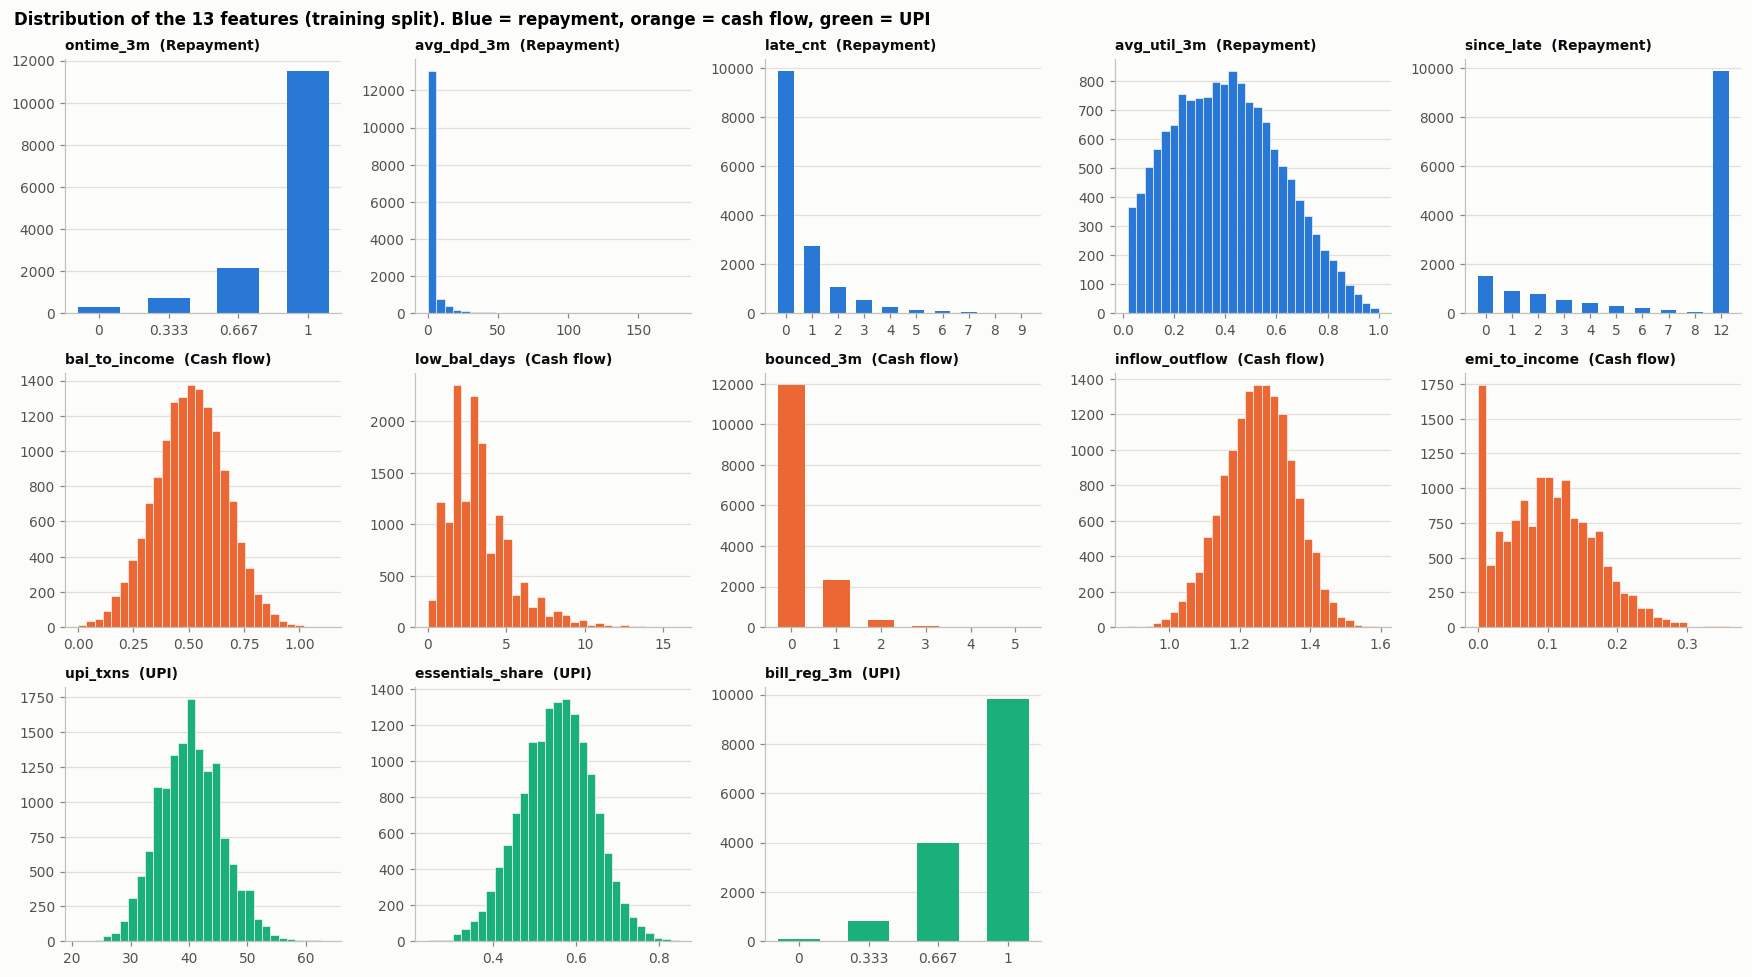

In [9]:
train = df[df["split"] == "train"].copy()
overall_rate = train[TARGET].mean()
print(f"Training rows: {len(train):,}, customers: {train['user_id'].nunique():,}, default rate: {overall_rate:.1%}")

fig, axes = plt.subplots(3, 5, figsize=(16, 9))
for ax, f in zip(axes.ravel(), FEATURES):
    colour = GROUP_COLOURS[GROUP_OF[f]]
    if train[f].nunique() <= 12:
        vc = train[f].value_counts().sort_index()
        ax.bar([f"{v:g}" for v in vc.index], vc.values, color=colour, width=0.6)
    else:
        ax.hist(train[f], bins=30, color=colour, edgecolor="#fcfcfb", linewidth=0.4)
    ax.set_title(f"{f}  ({GROUP_OF[f]})", fontsize=9)
for ax in axes.ravel()[len(FEATURES):]:
    ax.set_visible(False)
fig.suptitle("Distribution of the 13 features (training split). Blue = repayment, orange = cash flow, green = UPI",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**What we see:**
- **Repayment features are dominated by "good" values:** most customers paid every month on time (`ontime_3m` = 1), have 0 days past due, have never been late (`late_cnt` = 0, `since_late` = 12). Only a minority show any repayment problem, so these features mainly separate a **small group of visibly troubled customers** from everyone else.
- **Cash flow and UPI features are smooth, bell-shaped distributions** (balance, inflow/outflow, essentials share, UPI transactions). They vary across *all* customers, which lets them rank the whole population, not just the troubled minority.
- `emi_to_income` has a spike at 0: customers with no other loans.
- `low_bal_days` and `bounced_3m` are right-skewed: most customers have few low-balance days and no bounces.

## 7. How each feature relates to default (bivariate analysis)

#### What we're doing
For each feature, we split training rows into bands (one per value for discrete features, otherwise 10 equal-sized **deciles**) and plot the **default rate per band**. The dashed orange line is the overall training default rate (6.3%).

What to look for:
- **Big differences between bands** → a strong feature.
- **A steady rise or fall** → a **monotonic** relationship, ideal for a scorecard.
- **Flat, then a sudden jump** → a threshold effect.
- **Ups and downs** → a non-monotonic relationship, harder to explain.

Deciles mean every bar has about 1,470 rows, so differences aren't caused by tiny groups (except for rare discrete values).

#### How the code works
For each group, we make a grid of small charts and call `default_rate_chart(...)` (Section 1.2) once per feature. The x-axis labels show each band's value range.

### 7.1 Repayment features

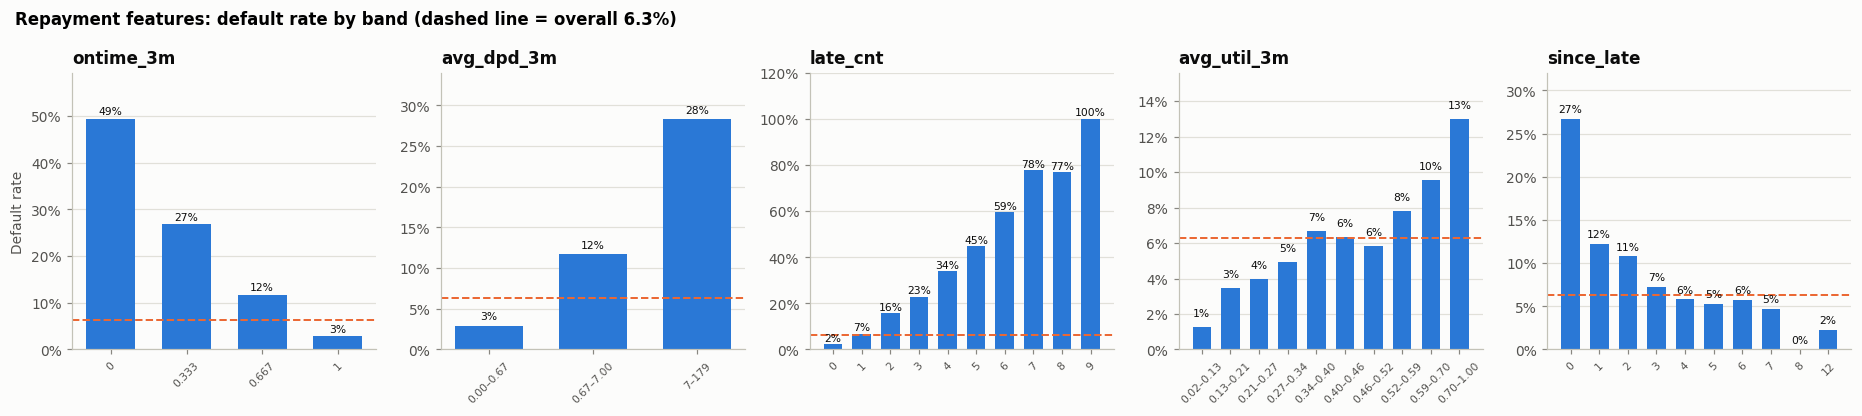

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
for ax, f in zip(axes, FEATURE_GROUPS["Repayment"]):
    default_rate_chart(train, f, ax, overall_rate)
axes[0].set_ylabel("Default rate")
fig.suptitle("Repayment features: default rate by band (dashed line = overall 6.3%)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**What we see:** all five behave as expected, and most show a **clear, steep** pattern:
- **`ontime_3m`:** all 3 months on time → 2.8% default; 2 of 3 → 12%; 1 of 3 → 27%; none → **49%**.
- **`late_cnt`:** 0 late months → 2.3%, rising steadily to 15.6% at 2, 34% at 4, and above 59% at 6 or more.
- **`avg_dpd_3m`:** most rows are at 0 days late (2.9% default); the most delinquent band (7+ days on average) → 28%. Only 3 bands appear, because most rows share the value 0.
- **`since_late`:** late **last month** (0) → 27% default, falling quickly as the late payment gets older. **Never late (12) → 2.3%**. Note that 8 months (0%, only 53 rows) and 7 months (4.7%) are *lower* than "never late". This is the **sentinel problem** from Section 3.1: in a model, 12 behaves like "a bit more than 8", which is roughly right here but is not guaranteed.
- **`avg_util_3m`** is the weakest: default rises gently from 1.3% at the lowest utilisation to 13% at the highest.

### 7.2 Cash flow features

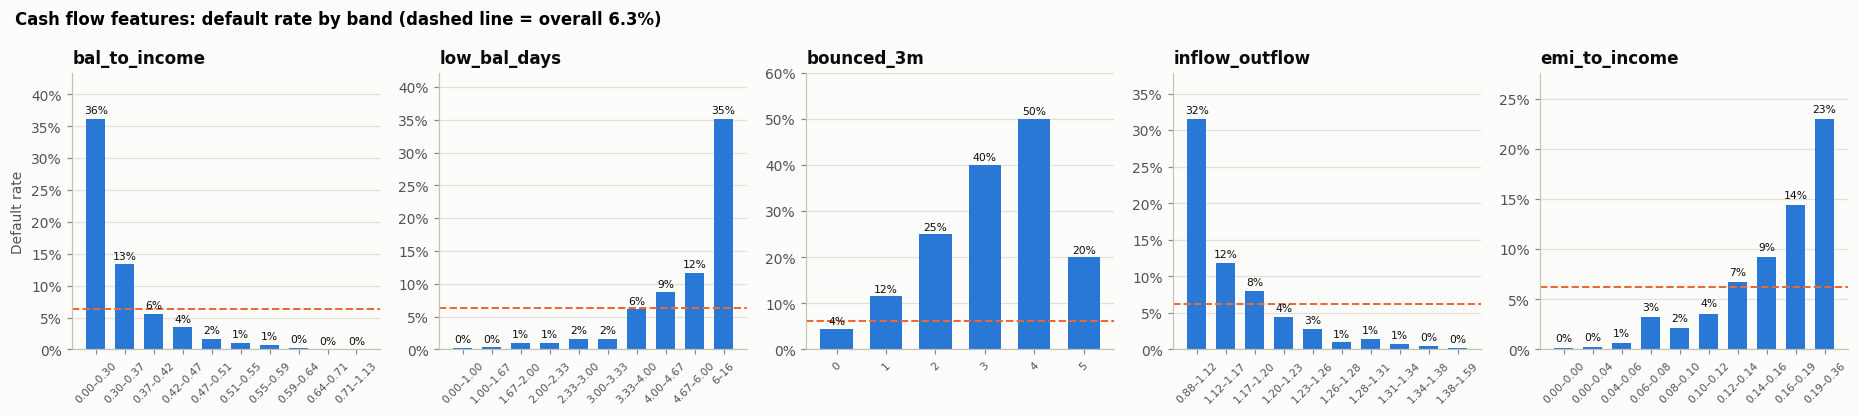

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
for ax, f in zip(axes, FEATURE_GROUPS["Cash flow"]):
    default_rate_chart(train, f, ax, overall_rate)
axes[0].set_ylabel("Default rate")
fig.suptitle("Cash flow features: default rate by band (dashed line = overall 6.3%)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**What we see:** these are the **strongest features in the dataset**, with very steep, smooth, monotonic patterns:
- **`bal_to_income`:** the lowest 10% (balance below 30% of income) → **36% default**; the next band → 13%; from the 5th decile upwards, default is **below 2%**, and the top band is **0%**.
- **`inflow_outflow`:** spending more than or nearly as much as earning (lowest band, ≤ 1.12) → **32%**; the top 6 bands are all at 1.4% or less.
- **`low_bal_days`:** a clear **threshold**: up to about 3 low-balance days a month, default stays at 0.3–1.6%; above 3.3 days it jumps to 6–12%; the worst band (6+ days) → **35%**.
- **`emi_to_income`:** existing loan instalments under ~6% of income → under 1% default, rising steadily to **23%** for the highest band (above ~19%).
- **`bounced_3m`:** 0 bounces → 4.5%; 1 → 11.5%; 2 → 25%. (The 4 and 5 values have only 14 and 5 rows; ignore their rates.)

### 7.3 UPI features

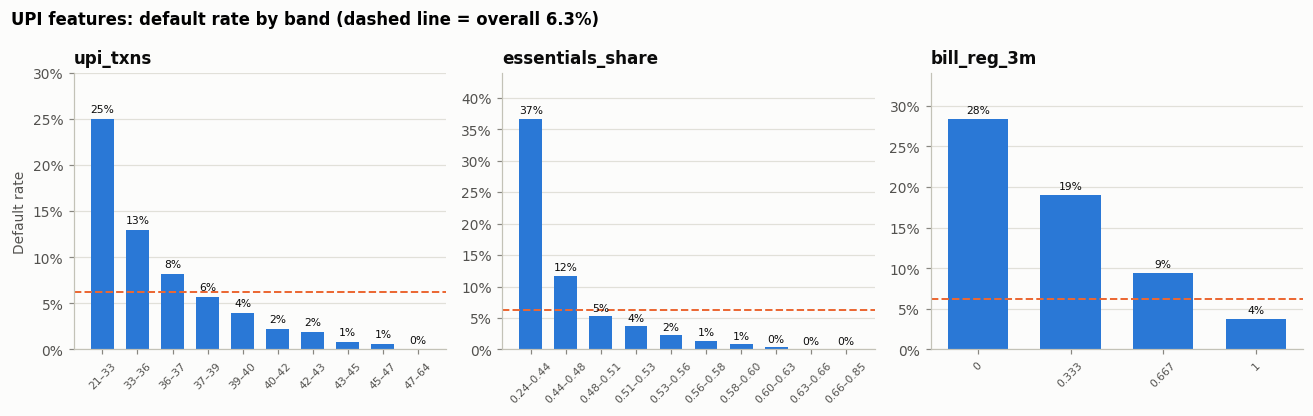

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, f in zip(axes, FEATURE_GROUPS["UPI"]):
    default_rate_chart(train, f, ax, overall_rate)
axes[0].set_ylabel("Default rate")
fig.suptitle("UPI features: default rate by band (dashed line = overall 6.3%)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**What we see:**
- **`essentials_share`** is almost as strong as bank balance: the lowest 10% (under 44% of spend on essentials) → **37% default**, falling to 0% for the top band. Customers who spend mostly on necessities rarely default; those spending mostly on non-essentials often do.
- **`upi_txns`:** fewer than ~33 UPI payments a month → 25% default, falling steadily to 0% above ~47. More UPI activity = a more active, visible financial life.
- **`bill_reg_3m`:** all bills on time → 3.8%, falling to 0 of 3 → 28% (but only 74 rows have 0).

## 8. Direction check and feature strength

#### What we're doing
Summarising Section 7 in one table, with four numbers per feature:

| Column | Meaning |
|---|---|
| **Mean if default / Mean if repaid** | Average feature value among defaulting rows vs repaying rows |
| **Correlation** | Correlation with the target (sign shows the direction) |
| **Direction as expected?** | Does the observed sign match the colleague's "higher value means" column? |
| **Single-feature AUC** | How well this feature *alone* ranks customers (0.5 = random, 1.0 = perfect). We flip the ranking when "higher = safer", so all values are ≥ 0.5. |
| **IV** | Information Value, the credit-industry standard |

The direction check matters for an explainable model: if a feature pointed the "wrong" way in the data, the model would have to tell customers something nonsensical (the colleague removed three features for this reason).

#### How the code works
- `roc_auc_score(y, x)` treats higher `x` as riskier; for "higher = safer" features we pass `-x` instead.
- `np.sign(correlation) == EXPECTED_DIRECTION[f]` is True when the observed direction matches.

In [13]:
rows = []
for f in FEATURES:
    corr = train[f].corr(train[TARGET])
    rows.append({
        "feature": f,
        "group": GROUP_OF[f],
        "mean if default": train.loc[train[TARGET] == 1, f].mean(),
        "mean if repaid": train.loc[train[TARGET] == 0, f].mean(),
        "correlation": corr,
        "direction as expected?": "Yes" if np.sign(corr) == EXPECTED_DIRECTION[f] else "NO",
        "single-feature AUC": roc_auc_score(train[TARGET], train[f] * EXPECTED_DIRECTION[f]),
        "IV": information_value(train[f], train[TARGET]),
    })
strength = pd.DataFrame(rows).set_index("feature").sort_values("IV", ascending=False)
strength.style.format({"mean if default": "{:.3f}", "mean if repaid": "{:.3f}", "correlation": "{:+.3f}",
                       "single-feature AUC": "{:.3f}", "IV": "{:.2f}"})

,group,mean if default,mean if repaid,correlation,direction as expected?,single-feature AUC,IV
feature,,,,,,,
bal_to_income,Cash flow,0.281,0.521,-0.368,Yes,0.897,3.72
essentials_share,UPI,0.431,0.561,-0.362,Yes,0.887,3.61
upi_txns,UPI,34.524,40.676,-0.276,Yes,0.818,2.39
low_bal_days,Cash flow,6.587,3.082,+0.412,Yes,0.869,2.29
inflow_outflow,Cash flow,1.127,1.261,-0.329,Yes,0.857,2.08
emi_to_income,Cash flow,0.173,0.096,+0.284,Yes,0.813,1.72
late_cnt,Repayment,2.207,0.492,+0.369,Yes,0.777,1.36
since_late,Repayment,3.690,9.070,-0.270,Yes,0.770,1.19
ontime_3m,Repayment,0.604,0.917,-0.345,Yes,0.752,1.18


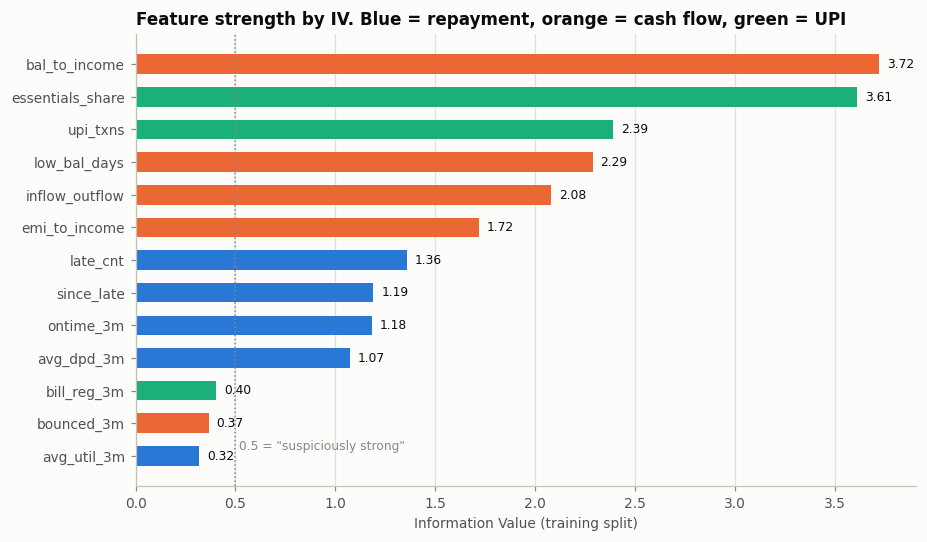

In [14]:
plot_df = strength.sort_values("IV")
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(plot_df.index, plot_df["IV"], color=[GROUP_COLOURS[g] for g in plot_df["group"]], height=0.6)
for y, v in enumerate(plot_df["IV"]):
    ax.text(v + 0.04, y, f"{v:.2f}", va="center", fontsize=8, color=INK)
ax.axvline(0.5, color=MUTED, linestyle=":", linewidth=1)
ax.text(0.52, 0.2, '0.5 = "suspiciously strong"', color=MUTED, fontsize=8)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Information Value (training split)")
ax.set_title("Feature strength by IV. Blue = repayment, orange = cash flow, green = UPI")
plt.tight_layout()
plt.show()

**What we see:**
- **All 13 features point in the expected direction.** This confirms the colleague's "sign check": there's no feature where, for example, more late payments would look safer.
- **The ranking matches the colleague's SHAP results:** cash flow and UPI features dominate. `bal_to_income` (IV 3.72, single-feature AUC 0.897) and `essentials_share` (IV 3.61, AUC 0.887) are the strongest, followed by `upi_txns`, `low_bal_days` and `inflow_outflow` (IV 2.1–2.4). The best repayment feature, `late_cnt`, is only 7th (IV 1.36). `bounced_3m`, `bill_reg_3m` and `avg_util_3m` are the weakest (IV 0.32–0.40).
- **These values are extraordinarily high.** The usual rule says IV above 0.5 is "suspiciously strong — check for leakage", and **every single feature is above 0.3; 10 of 13 are above 1**. In real credit data, a single feature with IV above 1 is very rare.
  - **`bal_to_income` alone reaches AUC 0.897**, higher than the colleague's final 13-feature model on the test set (0.884).
  - The colleague checked leakage properly (features use only the 3 months before, the target the 3 months after, and the split is by customer), so this is most likely **how the synthetic data was generated**: default was probably simulated directly from these cash-flow variables. The guide already says this openly in its Limitations.
- **Implication for the presentation:** the very high performance and the dominance of cash flow over repayment history should be presented as **properties of the synthetic data**, not as findings about real BNPL customers. On real data, expect lower AUC and a bigger role for repayment history.

## 9. How the features relate to each other

### 9.1 Correlation matrix

#### What we're doing
Checking which features **move together** (see the first EDA notebook, Section 8, for how to read a correlation heatmap). Features are ordered by group, so we can see whether correlation is mainly *within* groups or *across* them.

#### How the code works
`train[FEATURES].corr()` computes all pairwise correlations; `imshow` draws them with a blue (negative) → grey (zero) → red (positive) colour scale fixed at −1 to +1.

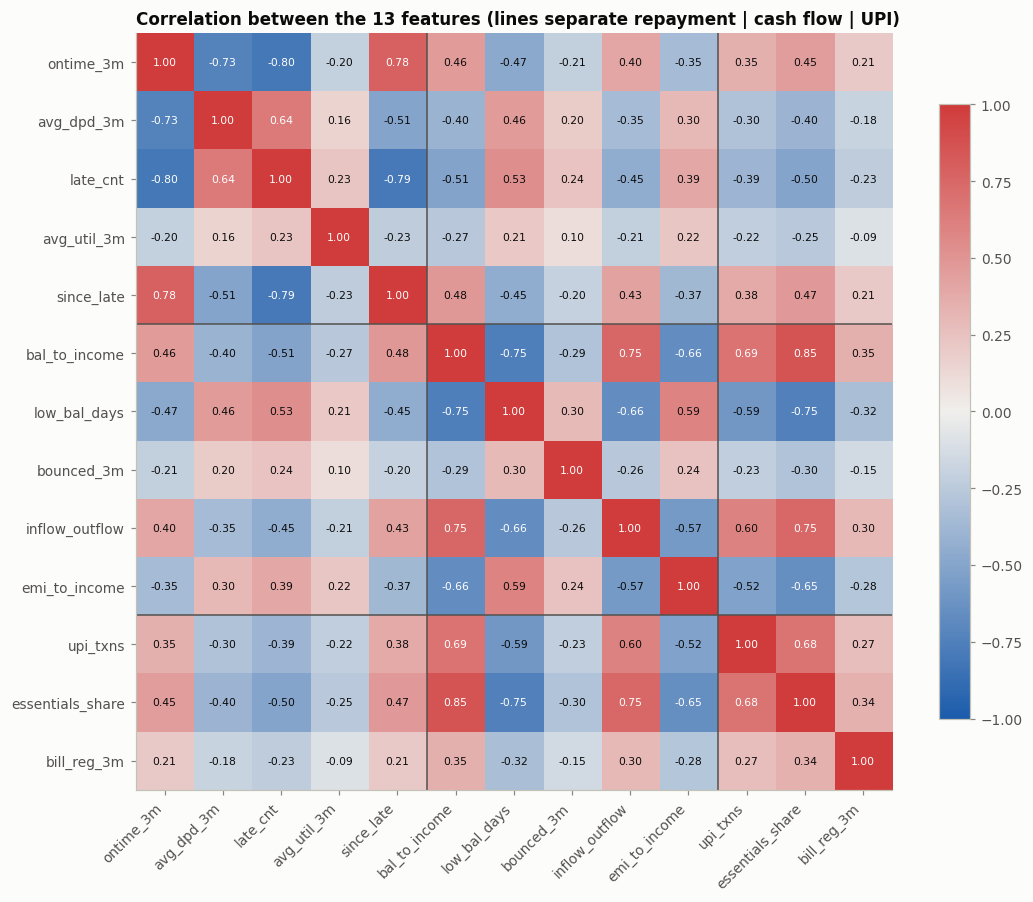

In [15]:
corr = train[FEATURES].corr()
diverging = LinearSegmentedColormap.from_list("blue_red", ["#1c5cab", "#f0efec", "#d03b3b"])

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
ax.grid(False)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else INK)
for edge in [4.5, 9.5]:   # group boundaries
    ax.axhline(edge, color=INK_2, linewidth=1)
    ax.axvline(edge, color=INK_2, linewidth=1)
fig.colorbar(im, ax=ax, shrink=0.75)
ax.set_title("Correlation between the 13 features (lines separate repayment | cash flow | UPI)")
plt.tight_layout()
plt.show()

**What we see:** two clusters of strongly related features.
1. **The repayment cluster:** `ontime_3m`, `late_cnt`, `since_late` and `avg_dpd_3m` (correlations 0.5–0.8 in size). They all describe the same thing, "has this customer been late?", from different angles.
2. **A "financial health" cluster that crosses the cash flow and UPI groups:** `bal_to_income`, `essentials_share`, `inflow_outflow`, `low_bal_days`, `upi_txns` and `emi_to_income` (correlations 0.5–0.85 in size). The strongest pair is **`bal_to_income` and `essentials_share` (0.85)**.

That second cluster is surprising. In real life, the share of spending on groceries and bills has no obvious reason to track bank balance so closely. Together with the very high IVs, it suggests the synthetic data was generated from a **single hidden "financial health" score** that drives all these features *and* default. That would explain why they are all so strong and so similar.

`avg_util_3m`, `bounced_3m` and `bill_reg_3m` are only weakly related to everything else; they carry more independent information.

### 9.2 Multicollinearity check (VIF)

#### What we're doing
Correlation looks at pairs; the **Variance Inflation Factor (VIF)** checks whether each feature can be predicted from **all the others combined** (explained in the modelling notebook, Section 5). VIF above 5 is worth watching, above 10 is serious. High VIF makes logistic regression coefficients unstable and can flip their signs, which is exactly the "backwards" problem the colleague solved by removing three features.

#### How the code works
For each feature, a linear regression predicts it from the other 12; VIF = 1 ÷ (1 − R²).

In [16]:
def vif(data, columns):
    out = {}
    for col in columns:
        y = data[col].values
        X = np.column_stack([data[[c for c in columns if c != col]].values, np.ones(len(data))])
        coef, *_ = np.linalg.lstsq(X, y, rcond=None)
        r2 = 1 - ((y - X @ coef) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        out[col] = 1 / (1 - r2)
    return pd.Series(out, name="VIF").sort_values(ascending=False).to_frame()

vif(train, FEATURES)

,VIF
bal_to_income,4.921
essentials_share,4.661
ontime_3m,4.576
late_cnt,3.928
since_late,3.541
low_bal_days,2.901
inflow_outflow,2.637
avg_dpd_3m,2.382
upi_txns,2.053
emi_to_income,1.934


**What we see:** every VIF is **below 5** (highest: `bal_to_income` 4.9, `essentials_share` 4.7, `ontime_3m` 4.6). The features overlap, but not enough to cause serious instability. This supports the colleague's choice: after removing the three duplicate features, the remaining 13 can be used together, and their logistic regression signs all come out the right way.

## 10. Stability: do the features change over time or between splits?

#### What we're doing
A model is trained on past customers and used on future ones. If a feature's distribution **shifts** over time, the model's learned relationships may no longer fit. The colleague's guide reports that model AUC **falls from 0.92 in months 3–6 to 0.84 in month 9**. Here we look for a cause.

We use **PSI** (Section 0) to compare each feature:
- **Train vs test:** are the test customers similar to the training customers?
- **Month 3 vs month 9:** has the feature drifted over time?

#### How the code works
`psi(expected, actual)` cuts both groups using the 10 band edges from the first group and adds up the differences. We compute it for every feature and both comparisons.

In [17]:
test = df[df["split"] == "test"]
stability = pd.DataFrame({
    "PSI train vs test": {f: psi(train[f], test[f]) for f in FEATURES},
    "PSI month 3 vs month 9": {f: psi(df.loc[df["month"] == 3, f], df.loc[df["month"] == 9, f]) for f in FEATURES},
})
stability["status (month 3 vs 9)"] = pd.cut(stability["PSI month 3 vs month 9"], [-1, 0.1, 0.25, 99],
                                            labels=["stable", "some shift", "major shift"])
stability.sort_values("PSI month 3 vs month 9", ascending=False).style.format(
    {"PSI train vs test": "{:.4f}", "PSI month 3 vs month 9": "{:.3f}"})

,PSI train vs test,PSI month 3 vs month 9,status (month 3 vs 9)
late_cnt,0.0003,0.222,some shift
upi_txns,0.0081,0.011,stable
low_bal_days,0.0038,0.009,stable
bal_to_income,0.0045,0.006,stable
inflow_outflow,0.0046,0.003,stable
essentials_share,0.0051,0.003,stable
avg_util_3m,0.0177,0.002,stable
bounced_3m,0.0006,0.002,stable
since_late,0.0002,0.001,stable
avg_dpd_3m,0.0017,0.001,stable


**What we see:**
- **Train vs test:** every PSI is below 0.02. The test customers look just like the training customers, so the colleague's test results are a fair measure.
- **Month 3 vs month 9:** 12 of 13 features are completely stable (PSI ≤ 0.011). **`late_cnt` is the exception, at 0.22**, close to the 0.25 "major shift" level.

Why? `late_cnt` counts late months **since the customer joined**, so it can only go up over time. A customer observed in month 9 has had three times as many months to be late as one observed in month 3. Let's look closer.

### 10.1 Why `late_cnt` drifts, and why it matters

#### What we're doing
Tracking `late_cnt` month by month: the share of customers with **2 or more late months**, and the default rate **among those customers**. If the feature meant the same thing every month, their default rate would stay roughly constant.

#### How the code works
- `train["late_cnt"] >= 2` flags customers with 2+ late months; `.groupby(train["month"]).mean()` gives the share per month.
- The default rate among flagged customers comes from filtering to them first, then grouping by month.
- Both lines are percentages, so they share one axis.

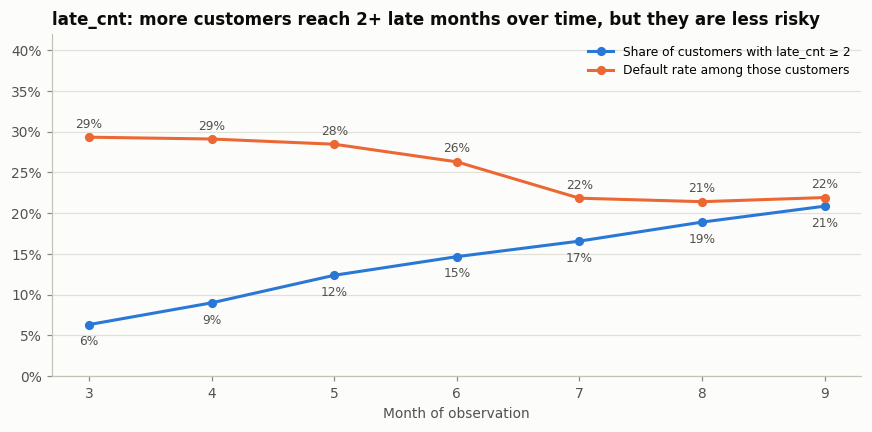

Mean late_cnt by month: {3: 0.29, 4: 0.39, 5: 0.49, 6: 0.59, 7: 0.71, 8: 0.81, 9: 0.91}


In [18]:
flag = train["late_cnt"] >= 2
share_flagged = flag.groupby(train["month"]).mean()
rate_flagged = train[flag].groupby("month")[TARGET].mean()
auc_by_month = train.groupby("month").apply(lambda g: roc_auc_score(g[TARGET], g["late_cnt"]), include_groups=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(share_flagged.index, share_flagged.values, marker="o", markersize=5, color=BLUE,
        label="Share of customers with late_cnt ≥ 2")
ax.plot(rate_flagged.index, rate_flagged.values, marker="o", markersize=5, color=ORANGE,
        label="Default rate among those customers")
for x, v in share_flagged.items():
    ax.text(x, v - 0.025, f"{v:.0%}", ha="center", fontsize=8, color=INK_2)
for x, v in rate_flagged.items():
    ax.text(x, v + 0.012, f"{v:.0%}", ha="center", fontsize=8, color=INK_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 0.42)
ax.set_xlabel("Month of observation")
ax.set_title("late_cnt: more customers reach 2+ late months over time, but they are less risky")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

print("Mean late_cnt by month:", train.groupby("month")["late_cnt"].mean().round(2).to_dict())

**What we see:**
- The share of customers with 2+ late months **more than triples**, from **6% in month 3 to 21% in month 9**, and the average `late_cnt` rises steadily.
- At the same time, the default rate among them **falls from 29% to 22%**.

**The meaning of `late_cnt` changes with time.** "2 late months" in month 3 means "late in 2 of the last 3 months", a serious warning sign. "2 late months" in month 9 might be two small slips spread over 9 months, much less worrying. A logistic regression gives `late_cnt` **one fixed weight for all months**, so it will over-penalise long-standing customers in later months.

This is a **plausible contributor to the colleague's finding that model accuracy falls in later months** (AUC 0.92 → 0.84). Other features are stable, so they can't explain it.

**Possible fix to suggest:** replace `late_cnt` with a **rate**, e.g. `late_cnt ÷ months observed` (the share of months paid late), or a fixed-window count such as "late months in the last 6 months". Both mean the same thing regardless of how long the customer has been with the lender.

## 11. Within-customer stability

#### What we're doing
Checking how much each feature changes **for the same customer** from month to month, compared with how much it varies **between customers**.

- **Ratio close to 0:** each customer's value barely moves; the feature behaves like a fixed "personality trait" of the customer.
- **Ratio close to 1:** the value moves around a lot month to month.

This helps interpret what the model is really learning: if the strongest features are almost constant per customer, the model is mostly identifying **types of customer**, not reacting to recent changes in behaviour.

#### How the code works
- `df.groupby("user_id")[f].std().mean()` is the average month-to-month spread *within* a customer.
- `df[f].std()` is the overall spread across all rows.
- The ratio of the two gives the "within-customer share" of variation.

In [19]:
within = pd.Series({f: df.groupby("user_id")[f].std().mean() / df[f].std() for f in FEATURES},
                   name="within-customer spread ÷ overall spread")
within = within.to_frame().join(strength[["IV"]]).sort_values("within-customer spread ÷ overall spread")
within.style.format({"within-customer spread ÷ overall spread": "{:.2f}", "IV": "{:.2f}"})

,within-customer spread ÷ overall spread,IV
emi_to_income,0.00,1.72
avg_util_3m,0.21,0.32
late_cnt,0.23,1.36
avg_dpd_3m,0.27,1.07
bal_to_income,0.29,3.72
since_late,0.31,1.19
essentials_share,0.32,3.61
low_bal_days,0.39,2.29
ontime_3m,0.41,1.18
inflow_outflow,0.47,2.08


**What we see:**
- **`emi_to_income` never changes for any customer** (ratio 0.00): each customer's EMI burden is fixed for all 7 months. In the synthetic data it was evidently set once per customer.
- **The two strongest features are also very stable:** `bal_to_income` (0.29) and `essentials_share` (0.32) barely move from month to month. Each customer essentially has a fixed balance level and spending mix.
- `upi_txns` (0.54) and `bill_reg_3m` (0.60) move the most, but even they vary less within a customer than between customers.

So the model's main skill is recognising **which type of customer** someone is (financially comfortable vs stretched), rather than spotting a customer whose situation is **getting worse**. That's useful, but a real lender would also want features that capture **change**, such as "balance fell 30% compared with 3 months ago".

## 12. Summary of findings

### Data quality
- **Clean:** 21,000 rows = 3,000 customers × 7 months (3–9), no missing values, no duplicates, all values plausible.
- **Split correctly by customer** (2,100 / 450 / 450), with similar default rates (6.3% / 6.2% / 5.9%). Train and test feature distributions are almost identical (PSI < 0.02).
- **`since_late = 12` is a sentinel** for "never late" (exactly matches `late_cnt = 0`), not a real number of months.

### Target
- **6.2% of customer-months default; 13.6% of customers default at least once.** The problem is imbalanced, so accuracy is not a useful metric.
- **Default is very sticky:** after a default month, the next month is also a default 76% of the time (overlapping 3-month windows). Rows from the same customer are not independent, so splitting by customer (as the colleague did) is essential, and any bootstrap should resample customers.

### The 13 features
| Finding | Detail |
|---|---|
| **All 13 point the expected way** | Confirms the colleague's sign check |
| **Cash flow and UPI dominate** | `bal_to_income` (IV 3.72, AUC 0.897) and `essentials_share` (IV 3.61, AUC 0.887) are strongest; best repayment feature `late_cnt` ranks 7th (IV 1.36) |
| **Strength is unrealistically high** | 10 of 13 features have IV above 1; one feature alone beats the full model's test AUC. Most likely a property of the synthetic data |
| **Two correlated clusters** | Repayment (`ontime_3m`, `late_cnt`, `since_late`, `avg_dpd_3m`) and financial health (`bal_to_income`, `essentials_share`, `inflow_outflow`, `low_bal_days`, `upi_txns`, `emi_to_income`); balance ↔ essentials share = 0.85 |
| **Multicollinearity acceptable** | All VIFs below 5 |
| **Clear thresholds** | Low-balance days above ~3.3 a month; balance below ~0.37 × income; inflow/outflow below ~1.17 |
| **`late_cnt` drifts over time** | PSI 0.22 (month 3 vs 9). Because it counts since joining, its meaning weakens in later months (default rate at 2+ late months: 29% → 22%) |
| **Features are fairly constant per customer** | `emi_to_income` is fixed per customer; the top two features barely move month to month. The model mostly identifies customer *types*, not deteriorating behaviour |

### Suggestions for the colleague's model
1. **Replace `late_cnt` with a time-independent version** (late months ÷ months observed, or late months in a fixed recent window). This may reduce the accuracy drop in later months.
2. **Treat `since_late = 12` explicitly**, e.g. add a `never_late` flag and cap `since_late` at 9, so "never late" is not modelled as "12 months ago".
3. **Present the dominance of cash flow and the high AUC as properties of the synthetic data.** The guide already does this in its Limitations; the IV and correlation evidence here supports it.
4. **Resample by customer** in any bootstrap confidence interval, because rows within a customer are strongly linked.
5. **Consider "change" features** (e.g. balance trend over the last 3 months) to catch customers whose situation is deteriorating.